# Agent 평가 실습: 호출 한도를 줄인 실행을 궤적과 운영 지표로 견주기

**이 노트북에서 할 일**

1. 03절의 평가받는 에이전트, 02절의 네 모드, 04절의 공통 칸을 한 흐름에 모읍니다.
2. 호출 한도 4인 실행 1과, 그 값 하나만 2로 줄인 실행 2를 차례로 실행합니다.
3. 두 실행을 네 모드와 공통 칸 두 줄로 견주어, 한도에 닿은 실행을 무엇이 가려내는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 실행 1과 실행 2에서 에이전트를 한 번씩 실행합니다.
노트북 밖에서 두 실행을 다섯 번씩 보냈을 때, 요청은 실행 1이 3번, 실행 2가 2번이었습니다.
그래서 이 노트북의 모델 요청은 모두 5번으로 어림하고, 평가 모델은 부르지 않습니다.
호출 한도를 붙여, 한 실행의 요청이 한도를 넘지 않게 막습니다.

요금표로 어림한 예상 비용은 두 실행을 합쳐 0.002달러 아래이고, 청구 금액이 아닙니다.
읽는 파일은 `.env`와 같은 폴더의 도구 파일 `eval_tools.py`이고, 쓰는 파일은 없습니다.
모델이 쓰는 답 글과 토큰 수는 실행마다 달라질 수 있고, 걸린 시간은 재지 않았습니다.
앞에서 배운 함수 일곱은 도구 파일에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 넷을 설치합니다.
판은 agentevals 0.0.9와 langchain 1.4.0입니다.
모델을 부르는 langchain-openai는 1.6.0, 키를 읽는 python-dotenv는 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었고, 다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 이 챕터의 실습이고, 30분 안팎입니다.
따로 내는 과제는 없고, 강사와 함께 첫 셀부터 차례로 실행합니다.

실습 폴더 `labs/part6/ch29-agent-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위 왼쪽 초록 상자 재료 03절과 같음, 질문 · 기준 궤적 · 도구 둘 · 시스템 메시지 글과, 오른쪽 파란 상자 바꾸는 값 호출 한도, 실행 1은 4 · 실행 2는 2에서 화살표가 파란 상자 조립 함수 run_agent, create_agent · 실행 한도 20 · invoke 한 번으로 모입니다. 이어서 보라 상자 gpt-5.4-mini 에이전트 요청, 노란 상자 결과 메시지 실행마다 궤적 하나로 화살표가 갑니다. 결과 메시지 상자에서 화살표 둘이 아래 파란 상자 둘로 갈라집니다. 왼쪽은 02절 four_modes 검색어를 뺀 모드 넷, 오른쪽은 count_asked · model_part · run_row · 04절 show_row, 03절 셈 · 공통 칸 한 줄인 그림](attachment:05-1-평가받는-에이전트와-두-평가의-조립.png)

위에서 아래로 읽습니다.
초록 상자는 03절과 같은 재료이고, 파란 상자는 바꾸는 값과 우리가 적거나 가져온 함수입니다.
보라 상자는 이 노트북이 실제로 부른 모델이고, 평가 모델은 부르지 않아 그리지 않았습니다.
노란 상자는 5절과 6절에서 함수 show_messages로 출력한 결과 메시지입니다.
아래 두 파란 상자는 같은 결과 메시지를 서로 다른 방법으로 보는 갈래이고, 서로의 차례가 아닙니다.
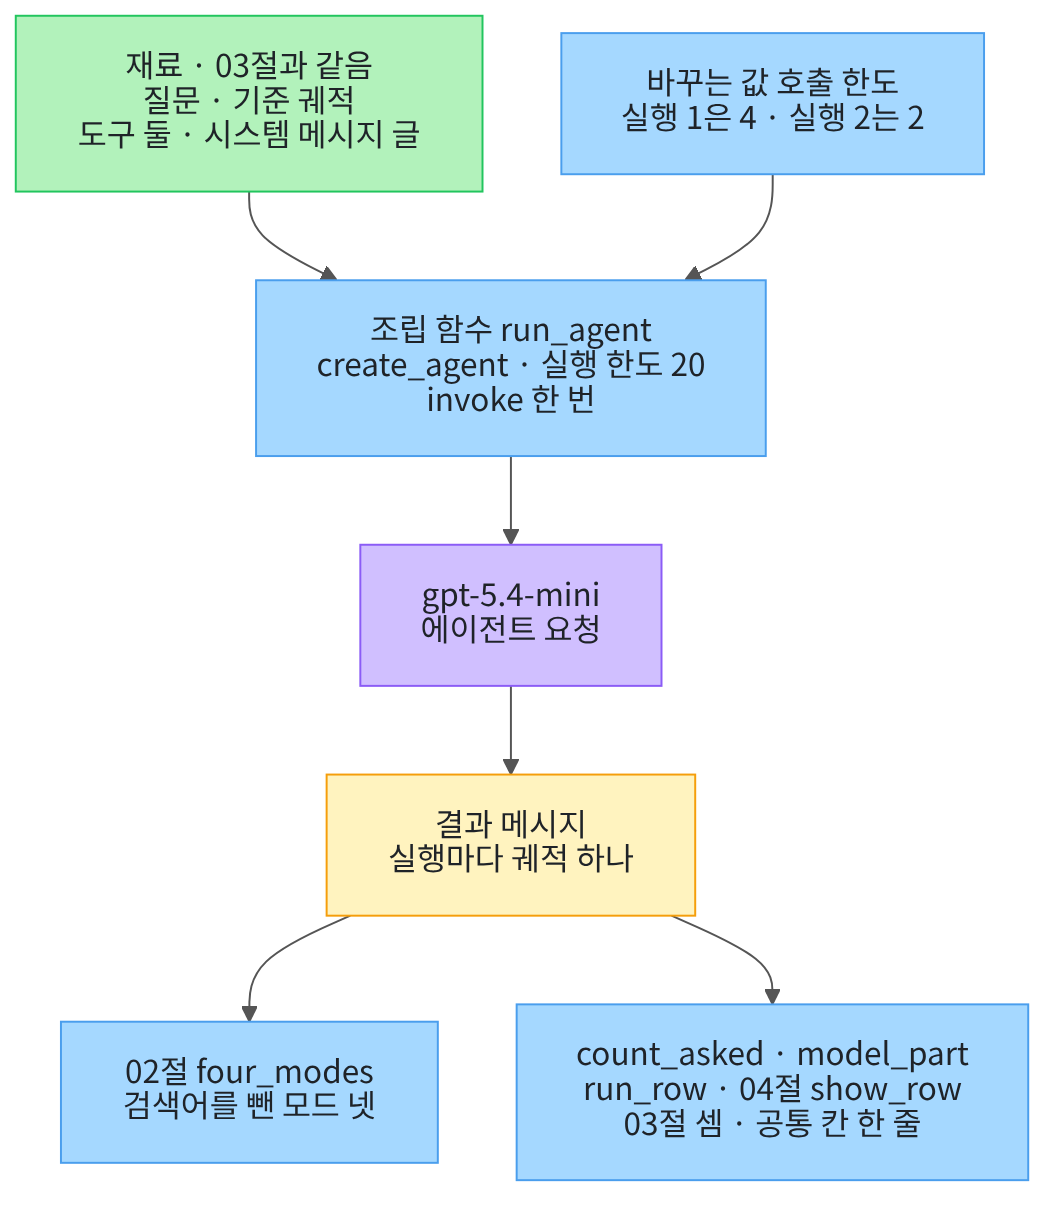

## 1. 준비

이 절은 Ch 29의 실습입니다.
01~04절에서 하나씩 본 기능 가운데 셋을, 도서관 규정에 답하는 에이전트 하나에 모읍니다.
03절의 평가받는 에이전트, 02절의 네 모드와 도구별 덮어쓰기, 04절의 공통 칸입니다.
그다음 호출 한도 하나만 바꿔 두 번 실행하고, 두 결과를 견줍니다.

첫 셀은 패키지 넷을 설치하고 설치된 판 번호를 출력합니다.
03절과 같은 넷이고, 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "agentevals==0.0.9" "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("agentevals:", version("agentevals"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
agentevals: 0.0.9
langchain: 1.4.0
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `agentevals: 0.0.9`, `langchain: 1.4.0`, `langchain-openai: 1.6.0`, `python-dotenv: 1.2.3`이 보입니다.
넷 모두 실습 폴더 잠금과 같은 판입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
03절처럼 평가 함수를 만드는 함수와, 에이전트·호출 한도·모델·메시지·도구 이름을 가져옵니다.
마지막 가져오기 줄은 앞에서 배운 함수 일곱을 도구 파일에서 가져옵니다.

In [2]:
# 궤적을 맞춰 보는 평가 함수를 만드는 함수와, 에이전트·호출 한도·모델·메시지·도구 이름을 가져옵니다(Ch 6·13·19·21·22)
from agentevals.trajectory.match import create_trajectory_match_evaluator
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langchain.tools import tool
# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from eval_tools import called_tool_names, four_modes, make_trajectory, show_messages, show_row, sum_usage, tool_call_names

print("도구 파일에서 가져온 함수:", "called_tool_names, four_modes, make_trajectory, show_messages, show_row, sum_usage, tool_call_names")

도구 파일에서 가져온 함수: called_tool_names, four_modes, make_trajectory, show_messages, show_row, sum_usage, tool_call_names


**결과 읽기** — 라벨 `도구 파일에서 가져온 함수:` 뒤에 `show_row`·`four_modes`·`sum_usage` 등 함수 일곱의 이름이 보입니다.
앞에서 배운 함수는 `eval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.

노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

함수 `show_row(row)`는 04절 노트북에서 처음 적은 함수이고, 이 절부터 도구 파일에서 가져옵니다.
도구 파일에는 04절 셀의 주석과 본문을 글자 그대로 옮겼고, 인자도 04절과 같습니다.
나머지 여섯은 03절에서도 가져온 이름입니다.
함수 `make_trajectory`·`called_tool_names`는 01절, `four_modes`는 02절에서 배웠습니다.
함수 `tool_call_names`·`sum_usage`·`show_messages`는 Ch 19 04~06절에서 배웠습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-29에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절과 6절의 실행 셀에서만 나갑니다.

## 2. 재료: 질문·기준 궤적·도구 둘

실습 재료는 03절과 같은 질문·기준 궤적·도구 둘입니다.
다음 셀은 03절 2절과 같은 질문·기준 답·결과 글을 정합니다.
아래에서 만들 도구 함수도 이 결과 글을 내놓습니다.

In [5]:
# 질문과 기준 답, 도구마다 돌아올 결과 글을 정합니다(03절 2절과 같은 값 — 아래 도구 함수도 이 글을 내놓음)
question = "일반 도서는 며칠 동안 빌릴 수 있나요?"
reference_answer = "일반 도서는 14일 동안 빌릴 수 있습니다."
tool_results = {
    "search_documents": "[LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.",
    "check_source": "LIB-001 문서가 있습니다. 제목: 도서 대출 기간",
}
print("질문:", question)
print("기준 답:", reference_answer)
print("결과 글을 정한 도구:", list(tool_results))

질문: 일반 도서는 며칠 동안 빌릴 수 있나요?
기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.
결과 글을 정한 도구: ['search_documents', 'check_source']


**결과 읽기** — 출력 줄 `기준 답: 일반 도서는 14일 동안 빌릴 수 있습니다.`가 보입니다.
라벨 `결과 글을 정한 도구:` 뒤에는 `'search_documents'`와 `'check_source'`가 있습니다.

다음 셀은 03절 2절과 같은 셀로, 도구 요청 둘로 기준 궤적을 만듭니다.

In [6]:
# 01절과 같은 도구 요청 둘로 기준 궤적을 만들고, 도구 차례와 메시지 수를 봅니다
search_args = {"query": "도서 대출 기간"}
source_args = {"doc_id": "LIB-001"}
reference_calls = [
    {"name": "search_documents", "args": search_args, "id": "call_1", "type": "tool_call"},
    {"name": "check_source", "args": source_args, "id": "call_2", "type": "tool_call"},
]
reference = make_trajectory(question, reference_calls, tool_results, reference_answer)
print("기준 궤적의 도구 차례:", called_tool_names(reference))
print("메시지 수:", len(reference))

기준 궤적의 도구 차례: ['search_documents', 'check_source']
메시지 수: 6


**결과 읽기** — 출력 줄 `기준 궤적의 도구 차례: ['search_documents', 'check_source']`와 `메시지 수: 6`이 보입니다.
검색한 뒤 출처를 확인하고 답하는, 01~03절과 같은 기준 궤적입니다.

다음 셀은 03절 4절과 같은 셀로, 검색 도구를 만듭니다.
03절처럼 `@tool` 줄은 아래 함수를 도구로 등록하고, 독스트링은 모델이 읽는 도구 설명이 됩니다.

In [7]:
# 검색 도구를 만듭니다(교재용 — 어떤 검색어에도 2절 결과 글 딕셔너리의 검색 결과 글을 내놓음)
@tool
def search_documents(query: str):
    """도서관 규정 문서를 검색어로 찾아, 문서 ID를 붙인 글로 내놓습니다."""
    return tool_results["search_documents"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 검색 도구는 교재용이라, 어떤 검색어에도 같은 검색 결과 글을 내놓습니다.

다음 셀도 03절 4절과 같은 셀로, 출처 확인 도구를 만듭니다.

In [8]:
# 출처 확인 도구를 만듭니다(문서 ID가 LIB-001일 때만 문서가 있다고 내놓음)
@tool
def check_source(doc_id: str):
    """문서 ID로 그 문서가 있는지 확인하고, 있으면 제목을 내놓습니다."""
    if doc_id == "LIB-001":
        return tool_results["check_source"]
    return doc_id + " 문서가 없습니다."

**결과 읽기** — 정의 셀이라 출력이 없습니다.
문서 ID가 `LIB-001`이면 출처 확인 결과 글을, 아니면 그 문서가 없다는 글을 내놓습니다.

검색어는 모델이 고르는 값이라, 기준 궤적의 검색어와 다를 수 있습니다.
그래서 03절 5절처럼 검색 도구의 인자만 보지 않는 평가 함수를 모드 넷마다 만듭니다.
02절 7절에서 본 도구별 덮어쓰기입니다.

In [9]:
# 검색 도구의 인자만 보지 않는 평가 함수를 모드 넷마다 만듭니다(03절 5절 — 02절 7절의 도구별 덮어쓰기)
modes = ["strict", "unordered", "subset", "superset"]
search_free = {}
for mode in modes:
    search_free[mode] = create_trajectory_match_evaluator(
        trajectory_match_mode=mode,
        tool_args_match_overrides={"search_documents": "ignore"},
    )
print("평가 함수를 만든 모드:", list(search_free))

평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']


**결과 읽기** — 출력 줄 `평가 함수를 만든 모드: ['strict', 'unordered', 'subset', 'superset']`이 보입니다.
네 평가 함수 모두 검색 도구 요청의 인자는 보지 않고, 출처 확인 요청의 인자는 그대로 견줍니다.
두 실행 모두 이 평가 함수 넷으로 판정합니다.

## 3. 조립하기

조립에는 03절 4절의 평가받는 에이전트를 씁니다.
다음 셀은 03절 4절과 같은 시스템 메시지 글과 실행 한도를 정합니다.
두 값은 두 실행에 같게 씁니다.

In [10]:
# 두 실행에 같게 쓸 시스템 메시지 글과 실행 한도를 정합니다(03절 4절 에이전트 셀과 같은 글·같은 값)
agent_rule = "도서관 규정 질문에는 먼저 search_documents로 문서를 찾고, 찾은 문서 ID로 check_source를 불러 문서가 있는지 확인한 뒤, 확인한 문서의 글만 근거로 한국어 한 문장으로 답하세요."
run_config = {"recursion_limit": 20}
print("시스템 메시지 글:", agent_rule)
print("실행 한도:", run_config["recursion_limit"])
print("두 값의 출처: 03절 4절 에이전트 셀(실행 전에 정함)")

시스템 메시지 글: 도서관 규정 질문에는 먼저 search_documents로 문서를 찾고, 찾은 문서 ID로 check_source를 불러 문서가 있는지 확인한 뒤, 확인한 문서의 글만 근거로 한국어 한 문장으로 답하세요.
실행 한도: 20
두 값의 출처: 03절 4절 에이전트 셀(실행 전에 정함)


**결과 읽기** — 라벨 `시스템 메시지 글:` 뒤에 검색한 뒤 출처를 확인하고 답하라는 글이 보입니다.
출력 줄 `실행 한도: 20`도 보입니다.
라벨 `두 값의 출처:` 뒤의 글은 두 값을 가져온 곳을 적어 둔 글이고, 코드가 견준 값은 아닙니다.
두 값은 실행 전에 정했고, 결과를 보고 바꾸지 않았습니다.

다음 셀은 호출 한도 하나를 받아, 에이전트를 만들고 한 번 실행하는 조립 함수입니다.
03절 4절의 에이전트 셀과 실행 셀을 한 함수로 모았습니다.
호출 한도만 인자로 받으므로, 두 실행 사이에 달라지는 것은 이 값 하나뿐입니다.

In [11]:
# 조립 함수입니다. 호출 한도 하나를 받아 평가받는 에이전트를 만들고, 질문 한 줄로 한 번 실행해 결과 메시지를 내놓습니다
def run_agent(limit):
    # Ch 22 04절: 한 번 실행에서 보낼 모델 요청 수를 limit으로 묶고, 닿으면 끝으로 갑니다
    call_limit = ModelCallLimitMiddleware(run_limit=limit, exit_behavior="end")
    # 03절 4절: 도구 둘·시스템 메시지 글을 붙인 에이전트를 만들어, 실행 한도를 주고 한 번 실행합니다
    agent = create_agent(model, tools=[search_documents, check_source], system_prompt=agent_rule, middleware=[call_limit])
    first_input = {"messages": [HumanMessage(content=question)]}
    result = agent.invoke(first_input, run_config)
    return result["messages"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 안에서 Ch 22 04절의 호출 한도를 실행마다 새로 만듭니다.
인자 `exit_behavior="end"`는 한도에 닿으면 오류 없이 끝으로 가게 합니다.
모델·도구 둘·시스템 메시지 글·질문·실행 한도는 앞 셀에서 만든 이름을 그대로 씁니다.

## 4. 결과를 볼 함수

두 실행을 같은 잣대로 보려고, 결과 메시지에서 값을 세는 함수 셋을 먼저 적습니다.
첫째 함수 `count_asked`는 도구를 요청한 응답 수를 셉니다.
03절 4절에서 셈 「요청 수 = 도구를 요청한 응답 수 + 1」을 확인한 셀의 반복문을 함수로 옮긴 모양입니다.

In [12]:
# 결과 메시지에서 도구 호출 요청이 하나라도 있는 모델 응답의 수를 세어 내놓습니다
def count_asked(messages):
    asked = 0
    for message in messages:
        if type(message).__name__ == "AIMessage":
            if len(tool_call_names(message)) > 0:
                asked = asked + 1
    return asked

**결과 읽기** — 정의 셀이라 출력이 없습니다.
응답(`AIMessage`)마다 도구 호출 요청의 이름을 모아, 하나라도 있으면 셉니다.

둘째 함수 `model_part`는 모델이 쓴 응답까지만 남긴 목록을 내놓습니다.
Ch 22 04절에서 본 것처럼, 호출 한도에 닿은 실행은 한도가 끼운 글로 끝납니다.
Ch 26 04절에서 본 것처럼, 그 끝 메시지는 모델 요청으로 받은 응답이 아니라 사용량 기록이 `None`입니다.
도구 파일 함수 `sum_usage`는 응답마다 사용량 기록을 더하므로, 이 메시지를 빼고 넘겨야 합니다.

In [13]:
# 마지막 메시지에 사용량 기록이 없으면(호출 한도가 끼운 글) 그 하나를 빼고, 모델이 쓴 응답까지의 목록을 내놓습니다
def model_part(messages):
    if messages[-1].usage_metadata is None:
        # 자르기 [:-1]은 맨 끝 하나를 뺀 앞부분입니다(Ch 26 05절)
        return messages[:-1]
    return messages

**결과 읽기** — 정의 셀이라 출력이 없습니다.
마지막 메시지의 사용량 기록이 `None`이면 그 하나를 빼고, 아니면 목록을 그대로 내놓습니다.
자르기 `[:-1]`은 Ch 26 05절에서 본 대로 맨 끝 하나를 뺀 앞부분입니다.

셋째 함수 `run_row`는 실행 한 번의 값을 04절 공통 칸 딕셔너리로 옮겨 담습니다.
칸 이름은 04절과 같은 여섯, 이름·요청 수·도구 요청 수·토큰 수·걸린 초·점수입니다.
걸린 초는 재지 않아, 04절에서 기록에 없는 칸을 둔 것처럼 모르는 값 `None`으로 둡니다.
점수 칸에는 두 실행 모두 같은 잣대인 모드 `strict`(검색어 뺌)의 판정을, 참이면 1.0으로 담습니다.

In [14]:
# 실행 한 번의 값을 04절 공통 칸 딕셔너리로 옮겨 담아 내놓습니다(걸린 초는 재지 않아 None, 점수는 참이면 1.0)
def run_row(name, messages, usage, score):
    return {
        "이름": name,
        "요청 수": usage["requests"],
        "도구 요청 수": len(called_tool_names(messages)),
        "토큰 수": usage["input_tokens"] + usage["output_tokens"],
        "걸린 초": None,
        "점수": float(score),
    }

**결과 읽기** — 정의 셀이라 출력이 없습니다.
04절 함수 `ch21_row`와 같은 모양으로, 칸 이름을 키로 한 딕셔너리를 내놓습니다.
도구 요청 수는 01절 함수 `called_tool_names`가 모은 도구 이름의 수입니다.
04절의 두 기록은 점수 칸의 잣대가 달라 견주지 않았지만, 이 절의 두 줄은 잣대가 같습니다.

## 5. 실행 1: 호출 한도 4

이제 실행 1을 합니다.
호출 한도는 03절과 같은 4이고, 03절 셈으로 이 궤적에 드는 요청 3번보다 한 번 여유가 있습니다.
실행 전에 예상해 봅니다.
03절과 같은 에이전트라면, 도구를 어떤 차례로 부르고 요청은 몇 번일까요?

In [15]:
# 실행 1: 호출 한도 4로 에이전트를 한 번 실행하고, 메시지를 차례대로 봅니다(모델 요청은 여기서 처음 나감)
first_limit = 4
first_messages = run_agent(first_limit)
print("호출 한도:", first_limit)
show_messages(first_messages)

호출 한도: 4
HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
AIMessage | 도구 호출 요청: ['check_source']
ToolMessage | 결과 상태: success | 내용: LIB-001 문서가 있습니다. 제목: 도서 대출 기간
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `호출 한도: 4`가 보입니다.
그 아래 `AIMessage | 도구 호출 요청: ['search_documents']`와 `AIMessage | 도구 호출 요청: ['check_source']`가 차례로 보입니다.
두 줄 뒤에는 `ToolMessage | 결과 상태: success`로 시작하는 줄이 하나씩 이어집니다.
마지막 줄 `AIMessage | 도구 호출 요청: []`는 도구를 요청하지 않은 응답입니다.

에이전트는 03절처럼 검색 → 출처 확인 → 마지막 응답의 차례로 움직였습니다.
도구를 부른 차례는 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 마지막 메시지의 글과, 그 메시지에 사용량 기록이 없는지 봅니다.

In [16]:
# 실행 1의 마지막 메시지 글과, 그 메시지에 사용량 기록이 없는지 봅니다(모델이 쓴 응답이면 기록이 있음)
first_last = first_messages[-1]
print("마지막 메시지 글:", first_last.content)
print("사용량 기록이 없는가:", first_last.usage_metadata is None)

마지막 메시지 글: 일반 도서는 14일 동안 빌릴 수 있습니다.
사용량 기록이 없는가: False


**결과 읽기** — 출력 줄 `사용량 기록이 없는가: False`가 보입니다.
라벨 `마지막 메시지 글:` 뒤에는 모델이 쓴 답이 있습니다.
사용량 기록이 있으니, 마지막 메시지는 모델 요청으로 받은 응답입니다.

이번 실행에서는 답 글이 기준 답 「일반 도서는 14일 동안 빌릴 수 있습니다」와 글자까지 같았습니다.
답 글은 모델이 쓴 글이라 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.

다음 셀은 함수 `model_part`로 끝 메시지를 뺀 목록을 받아 모델 요청 수를 세고, 03절 셈과 견줍니다.
실행 1은 마지막 메시지에 사용량 기록이 있어, 뺄 메시지가 없을 것입니다.

In [17]:
# 실행 1에서 끝 메시지를 뺀 목록으로 모델 요청 수(Ch 19 05절 함수 sum_usage)를 세고, 03절 셈과 견줍니다
first_kept = model_part(first_messages)
first_usage = sum_usage(first_kept)
first_asked = count_asked(first_messages)
first_formula = first_usage["requests"] == first_asked + 1
print("끝에서 뺀 메시지 수:", len(first_messages) - len(first_kept))
print("도구를 요청한 응답 수:", first_asked)
print("모델 요청 수:", first_usage["requests"])
print("모델 요청 수 = 도구를 요청한 응답 수 + 1:", first_formula)

끝에서 뺀 메시지 수: 0
도구를 요청한 응답 수: 2
모델 요청 수: 3
모델 요청 수 = 도구를 요청한 응답 수 + 1: True


**결과 읽기** — 출력 줄 `끝에서 뺀 메시지 수: 0`, `도구를 요청한 응답 수: 2`, `모델 요청 수: 3`이 보입니다.
출력 줄 `모델 요청 수 = 도구를 요청한 응답 수 + 1: True`로, 03절 셈이 맞았습니다.
도구를 요청한 응답 둘에, 답을 쓴 응답 하나가 더해졌습니다.
요청 3번은 호출 한도 4 안이라, 실행이 답까지 갔습니다.

다음 셀은 실행 1의 궤적을 검색어를 빼고 네 모드로 견줍니다.

In [18]:
# 실행 1의 궤적을 검색어를 빼고 네 모드로 기준 궤적과 견줍니다(02절 함수 four_modes)
first_modes = four_modes(first_messages, reference, search_free)
print("실행 1:", first_modes)

실행 1: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}


**결과 읽기** — 출력 줄 `실행 1: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}`가 보입니다.
03절 5절처럼 네 모드 모두 참이었습니다.
검색어를 빼고 보면, 실행 1은 기준 궤적과 같은 도구를 같은 차례로 불렀습니다.

## 6. 실행 2: 호출 한도 2

실행 2는 값 하나만 바꿉니다.
호출 한도를 4에서 2로 줄이고, 질문·도구·시스템 메시지 글·실행 한도·조립 함수는 실행 1과 같게 둡니다.
03절 셈으로 이 궤적에는 요청이 3번 듭니다.
Ch 22 04절에서 본 것처럼 호출 한도는 모델 요청 전에 센 수를 보므로, 한도 2면 셋째 요청 전에 멈춥니다.

실행 전에 예상해 봅니다.
메시지를 차례대로 보는 출력은 실행 1과 어떻게 다를까요?
네 모드의 판정은 실행 1과 같을까요, 달라질까요?

In [19]:
# 실행 2: 값 하나만 바꿉니다. 호출 한도를 2로 줄여 같은 질문으로 한 번 실행하고, 메시지를 차례대로 봅니다
second_limit = 2
second_messages = run_agent(second_limit)
print("호출 한도:", second_limit)
show_messages(second_messages)

호출 한도: 2
HumanMessage
AIMessage | 도구 호출 요청: ['search_documents']
ToolMessage | 결과 상태: success | 내용: [LIB-001] 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
AIMessage | 도구 호출 요청: ['check_source']
ToolMessage | 결과 상태: success | 내용: LIB-001 문서가 있습니다. 제목: 도서 대출 기간
AIMessage | 도구 호출 요청: []


**결과 읽기** — 출력 줄 `호출 한도: 2`가 보입니다.
그 아래 줄은 실행 1의 출력과 한 줄도 다르지 않습니다.
도구 호출 요청 두 줄과 도구 메시지 두 줄이 같은 차례로 있고, 마지막 줄도 `AIMessage | 도구 호출 요청: []`입니다.

함수 `show_messages`는 메시지의 종류와 도구 요청, 도구 결과만 보여 줍니다.
그래서 이 출력만으로는 실행 2가 한도에 닿았는지 보이지 않습니다.
도구 요청 둘은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 실행 1과 같았습니다.

다음 셀은 실행 1처럼 마지막 메시지의 글과 사용량 기록을 봅니다.

In [20]:
# 실행 2의 마지막 메시지 글과, 그 메시지에 사용량 기록이 없는지 봅니다
second_last = second_messages[-1]
print("마지막 메시지 글:", second_last.content)
print("사용량 기록이 없는가:", second_last.usage_metadata is None)

마지막 메시지 글: Model call limits exceeded: run limit (2/2)
사용량 기록이 없는가: True


**결과 읽기** — 출력 줄 `마지막 메시지 글: Model call limits exceeded: run limit (2/2)`와 `사용량 기록이 없는가: True`가 보입니다.
마지막 메시지는 모델이 쓴 답이 아니라, 호출 한도가 끼운 글입니다.
글 끝의 `(2/2)`는 센 요청 수 2가 한도 2에 닿았다는 뜻입니다.

이 끝 메시지는 설치판 langchain 1.4.0 `agents/middleware/model_call_limit.py` 37~60행이 만듭니다.
에이전트는 출처 확인 결과까지 받았지만, 그 결과를 읽고 답할 셋째 요청은 나가지 않았습니다.

다음 셀은 실행 2에서도 요청 수를 세어 03절 셈과 견줍니다.
함수 `model_part`가 끝 메시지를 빼고 함수 `sum_usage`에 넘깁니다.

In [21]:
# 실행 2에서도 끝 메시지를 뺀 목록으로 모델 요청 수를 세고, 03절 셈과 견줍니다
second_kept = model_part(second_messages)
second_usage = sum_usage(second_kept)
second_asked = count_asked(second_messages)
second_formula = second_usage["requests"] == second_asked + 1
print("끝에서 뺀 메시지 수:", len(second_messages) - len(second_kept))
print("도구를 요청한 응답 수:", second_asked)
print("모델 요청 수:", second_usage["requests"])
print("모델 요청 수 = 도구를 요청한 응답 수 + 1:", second_formula)

끝에서 뺀 메시지 수: 1
도구를 요청한 응답 수: 2
모델 요청 수: 2
모델 요청 수 = 도구를 요청한 응답 수 + 1: False


**결과 읽기** — 출력 줄 `끝에서 뺀 메시지 수: 1`이 보입니다.
출력 줄 `도구를 요청한 응답 수: 2`와 `모델 요청 수: 2`도 보입니다.
출력 줄 `모델 요청 수 = 도구를 요청한 응답 수 + 1: False`로, 03절 셈이 맞지 않았습니다.
답을 쓴 응답이 없어, 요청 수가 도구를 요청한 응답 수와 같습니다.

03절 셈은 답까지 간 실행에서 맞는 셈이고, 한도에 닿은 이 실행에서는 1이 모자랐습니다.
요청 수와 셈은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 실행 2의 궤적을 실행 1과 같은 네 모드로 견줍니다.

In [22]:
# 실행 2의 궤적도 실행 1과 같은 네 평가 함수로 기준 궤적과 견줍니다
second_modes = four_modes(second_messages, reference, search_free)
print("실행 2:", second_modes)

실행 2: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}


**결과 읽기** — 출력 줄 `실행 2: {'strict': True, 'unordered': True, 'subset': True, 'superset': True}`가 보입니다.
답을 쓰지 못한 실행 2도 네 모드 모두 참이었습니다.

01·02절에서 본 것처럼, 네 모드는 도구 요청을 견주고 메시지 글은 견주지 않습니다.
모드 `strict`는 메시지 수·역할·차례까지 보지만, 실행 2는 끝 메시지도 도구를 요청하지 않는 응답이라 그것까지 같습니다.
그래서 호출 한도가 끼운 끝 메시지도 모드에게는 기준 궤적의 답과 같은 자리의 응답으로 보입니다.
이 판정도 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

## 7. 두 실행 견주기

마지막으로 두 실행을 04절 공통 칸 두 줄로 옮겨 담아 한 표로 봅니다.
04절 함수 `show_row`는 공통 칸 딕셔너리 한 줄을 「|」로 이어 출력합니다.

In [23]:
# 두 실행을 04절 공통 칸 두 줄로 옮겨 담고, 04절 함수 show_row로 한 표에 출력합니다(점수 칸은 모드 strict 판정)
first_row = run_row("실행 1(한도 4)", first_messages, first_usage, first_modes["strict"])
second_row = run_row("실행 2(한도 2)", second_messages, second_usage, second_modes["strict"])
rows = [first_row, second_row]
print("이름 | 요청 수 | 도구 요청 수 | 토큰 수 | 걸린 초 | 점수")
for row in rows:
    show_row(row)

이름 | 요청 수 | 도구 요청 수 | 토큰 수 | 걸린 초 | 점수
실행 1(한도 4) | 3 | 2 | 996 | None | 1.0
실행 2(한도 2) | 2 | 2 | 615 | None | 1.0


**결과 읽기** — 라벨 줄 `이름 | 요청 수 | 도구 요청 수 | 토큰 수 | 걸린 초 | 점수` 아래 두 줄이 보입니다.
두 줄 모두 도구 요청 수 칸이 `2`, 걸린 초 칸이 `None`, 점수 칸이 `1.0`입니다.
요청 수 칸만 실행 1이 `3`, 실행 2가 `2`로 다릅니다.
점수 칸만 보면 두 실행은 같은 줄로 보입니다.

이번 실행에서는 토큰 수 칸이 실행 1 996, 실행 2 615였습니다.
실행 2에는 셋째 요청이 없어 토큰 수가 적었습니다.
토큰 수는 실행마다 달라질 수 있어 결론에 쓰지 않습니다.

다음 셀은 두 실행 가운데 점수가 1.0인 실행과, 03절 셈이 맞은 실행을 셉니다.
04절 5절에서 잘됐다고 적은 줄을 센 것과 같은 모양입니다.

In [24]:
# 두 실행 가운데 점수 칸이 1.0인 실행과, 03절 셈이 맞은 실행을 셉니다(04절 5절처럼 세는 값으로 읽기)
score_count = 0
for row in rows:
    if row["점수"] == 1.0:
        score_count = score_count + 1
formula_count = 0
for formula in [first_formula, second_formula]:
    if formula:
        formula_count = formula_count + 1
print("점수가 1.0인 실행:", score_count, "| 셈이 맞은 실행:", formula_count, "| 전체 실행:", len(rows))

점수가 1.0인 실행: 2 | 셈이 맞은 실행: 1 | 전체 실행: 2


**결과 읽기** — 출력 줄 `점수가 1.0인 실행: 2 | 셈이 맞은 실행: 1 | 전체 실행: 2`가 보입니다.
궤적 맞춰 보기로는 두 실행이 모두 통과했지만, 03절 셈이 맞은 것은 답까지 간 실행 1뿐입니다.

모드는 도구를 기준대로 불렀는지를 봅니다.
요청 수 셈과 끝 메시지는 실행이 어떻게 끝났는지를 봅니다.
도구를 모두 부른 뒤 한도에 닿은 실행은, 궤적 맞춰 보기와 함께 운영 지표를 봐야 가려낼 수 있습니다.
두 수는 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

## 정리

1. 03절의 평가받는 에이전트, 02절의 네 모드와 도구별 덮어쓰기, 04절의 공통 칸을 한 흐름에 모았습니다.
2. 호출 한도를 4에서 2로 줄이자, 실행 2는 도구 둘을 부른 뒤 한도가 끼운 글로 끝났고 03절 셈이 `False`였습니다.
3. 두 실행 모두 네 모드가 참이었고, 한도에 닿은 실행은 요청 수 셈과 끝 메시지로 가려냈습니다. 2·3번의 값은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

이 절로 Ch 29와 Part 6이 끝납니다.
다음 학습은 Part 7 Ch 30 01절입니다. 그 절에서는 웹 서비스가 받을 요청과 내놓을 응답의 모양을 정합니다.